In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path


In [2]:
df = pd.read_csv("../data/processed/deneme1.csv")


In [3]:
y = df["price"]
X = df.drop(columns=["price", "price_per_sqm", "listing_id", "total_rooms", "orientation"])

In [4]:
X_train = X.sample(frac=0.70, random_state=42).copy()
X_kalan = X.drop(index=X_train.index)

X_val = X_kalan.sample(frac=0.50, random_state=42).copy()
X_test = X_kalan.drop(index=X_val.index).copy()

y_train = y.loc[X_train.index]
y_val = y.loc[X_val.index]
y_test = y.loc[X_test.index]

In [5]:
sutunlar = ["bathroom_count", "total_floors"]

medyanlar = X_train[sutunlar].median()

X_train[sutunlar] = X_train[sutunlar].fillna(medyanlar)
X_val[sutunlar] = X_val[sutunlar].fillna(medyanlar)
X_test[sutunlar] = X_test[sutunlar].fillna(medyanlar)

In [6]:
for veri in [X_train, X_val, X_test]:
    veri["exchange"] = (veri["exchange"] == "Yes").astype(int)
    veri["credit_eligible"] = (veri["credit_eligible"] == "Eligible").astype(int)
    veri["furnished"] = (veri["furnished"] == "Furnished").astype(int)
    veri["is_in_complex"] = veri["is_in_complex"].astype(int)
    veri["is_top_floor"] = veri["is_top_floor"].fillna(False).astype(int)
    veri["is_ground_floor"] = veri["is_ground_floor"].fillna(False).astype(int)

In [7]:
for veri in [X_train, X_val, X_test]:
    veri["usage_status"] = veri["usage_status"].replace("Not Specified", pd.NA)

kategorikler = ["district", "neighborhood", "heating_type", "usage_status", "deed_status"]

X_train = pd.get_dummies(X_train, columns=kategorikler, dtype=int)
X_val = pd.get_dummies(X_val, columns=kategorikler, dtype=int)
X_test = pd.get_dummies(X_test, columns=kategorikler, dtype=int)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [8]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (17327, 650)
Validation: (3713, 650)
Test: (3713, 650)


In [9]:
print("Train eksik:", X_train.isna().sum().sum())
print("Validation eksik:", X_val.isna().sum().sum())
print("Test eksik:", X_test.isna().sum().sum())

Train eksik: 0
Validation eksik: 0
Test eksik: 0


## 1. Sayisal verileri normalize etme

In [10]:
sayisal = ["rooms", "halls", "gross_sqm", "net_sqm", "total_floors", "building_age", "bathroom_count"]

ortalama = X_train[sayisal].mean()
standart_sapma = X_train[sayisal].std().replace(0, 1)

for veri in [X_train, X_val, X_test]:
    veri[sayisal] = (veri[sayisal] - ortalama) / standart_sapma

print("Train eksik:", X_train.isna().sum().sum())
print("Validation eksik:", X_val.isna().sum().sum())
print("Test eksik:", X_test.isna().sum().sum())

Train eksik: 0
Validation eksik: 0
Test eksik: 0


## 2. Cephe bilgisi (ikinci deney)

CSV'de `North`, `South`, `East`, `West` degerleri virgul ile ayrilmis. Bir ilanda birden fazla yon bulunabiliyor. Bu nedenle 4 yon + `Unknown` ile Multi-Hot Encoding kullaniyoruz. `Fourplex` bir yon olmadigi icin `Unknown` kabul ediliyor. `01_explore_data.ipynb` degismiyor.

In [11]:
yonler = {
    "North": "cephe_kuzey",
    "South": "cephe_guney",
    "East": "cephe_dogu",
    "West": "cephe_bati",
}


def cephe_ekle(veri):
    yon_bilgileri = df.loc[veri.index, "orientation"].fillna("").str.split(",")
    cepheler = pd.DataFrame(index=veri.index)

    for yon, sutun in yonler.items():
        cepheler[sutun] = yon_bilgileri.apply(
            lambda parcalar: int(yon in [parca.strip() for parca in parcalar])
        )

    cepheler["cephe_unknown"] = (cepheler.sum(axis=1) == 0).astype(int)
    return pd.concat([veri, cepheler], axis=1)


X_train_cepheli = cephe_ekle(X_train)
X_val_cepheli = cephe_ekle(X_val)
X_test_cepheli = cephe_ekle(X_test)

print("Cephe olmayan giris sayisi:", X_train.shape[1])
print("Cepheli giris sayisi:", X_train_cepheli.shape[1])
print("Train bilinmeyen cephe:", X_train_cepheli["cephe_unknown"].sum())
print("Validation bilinmeyen cephe:", X_val_cepheli["cephe_unknown"].sum())
print("Test bilinmeyen cephe:", X_test_cepheli["cephe_unknown"].sum())


Cephe olmayan giris sayisi: 650
Cepheli giris sayisi: 655
Train bilinmeyen cephe: 3759
Validation bilinmeyen cephe: 778
Test bilinmeyen cephe: 774


## 3. TensorFlow icin verileri hazirlama

In [12]:
tf.random.set_seed(42)
np.random.seed(42)

X_train_tf = tf.constant(X_train.to_numpy(dtype=np.float32))
X_val_tf = tf.constant(X_val.to_numpy(dtype=np.float32))
X_test_tf = tf.constant(X_test.to_numpy(dtype=np.float32))

y_train_tf = tf.constant(y_train.to_numpy(dtype=np.float32).reshape(-1, 1) / 1_000_000)
y_val_tf = tf.constant(y_val.to_numpy(dtype=np.float32).reshape(-1, 1) / 1_000_000)

print("Giris ozellik sayisi:", X_train_tf.shape[1])
print("Train / Validation / Test:", len(y_train), len(y_val), len(y_test))

Giris ozellik sayisi: 650
Train / Validation / Test: 17327 3713 3713


In [13]:
X_train_tf_cepheli = tf.constant(X_train_cepheli.to_numpy(dtype=np.float32))
X_val_tf_cepheli = tf.constant(X_val_cepheli.to_numpy(dtype=np.float32))
X_test_tf_cepheli = tf.constant(X_test_cepheli.to_numpy(dtype=np.float32))


## 4. Uc ANN mimarisi, iki veri secenegi

Ayni train/validation/test ayrimi ve egitim ayarlariyla `50-25`, `100-50`, `150-100` mimarilerini cepheli/cephesiz karsilastiriyoruz. Daha once egitilen cephesiz modellerin checkpoint ve sonuc dosyalari varsa yeniden egitmiyoruz.

In [14]:
mimariler = [(100, 50), (50, 25), (150, 100)]

modeller_klasoru = Path("../models")
sonuclar_klasoru = Path("../results")
modeller_klasoru.mkdir(parents=True, exist_ok=True)
sonuclar_klasoru.mkdir(parents=True, exist_ok=True)

## 5. TensorFlow ile ANN egitimi

Keras kullanmadan `tf.Variable`, `tf.GradientTape` ve Adam ile egitim yapiyoruz. En dusuk validation MSE agirliklari saklaniyor. Maksimum 150 epoch, patience 15, batch size 64.

In [15]:
def model_olustur(birinci, ikinci, giris):
    w1 = tf.Variable(tf.random.normal([giris, birinci], stddev=(2.0 / giris) ** 0.5))
    b1 = tf.Variable(tf.zeros([birinci]))

    w2 = tf.Variable(tf.random.normal([birinci, ikinci], stddev=(2.0 / birinci) ** 0.5))
    b2 = tf.Variable(tf.zeros([ikinci]))

    w3 = tf.Variable(tf.random.normal([ikinci, 1], stddev=(2.0 / ikinci) ** 0.5))
    b3 = tf.Variable(tf.zeros([1]))

    return [w1, b1, w2, b2, w3, b3]


def tahmin(x, parametreler):
    w1, b1, w2, b2, w3, b3 = parametreler
    x = tf.nn.relu(tf.matmul(x, w1) + b1)
    x = tf.nn.relu(tf.matmul(x, w2) + b2)
    return tf.matmul(x, w3) + b3


In [16]:
def modeli_egit(birinci, ikinci, cepheli=False):
    isim = f"ann_{birinci}_{ikinci}"

    if cepheli:
        isim += "_cepheli"
        X_egitim_tf = X_train_tf_cepheli
        X_dogrulama_tf = X_val_tf_cepheli
        sutun_isimleri = X_train_cepheli.columns.to_numpy()
    else:
        X_egitim_tf = X_train_tf
        X_dogrulama_tf = X_val_tf
        sutun_isimleri = X_train.columns.to_numpy()

    tf.random.set_seed(42)
    parametreler = model_olustur(birinci, ikinci, int(X_egitim_tf.shape[1]))
    optimizer = tf.optimizers.Adam(learning_rate=0.001)

    train_verisi = tf.data.Dataset.from_tensor_slices((X_egitim_tf, y_train_tf))
    train_verisi = train_verisi.shuffle(len(y_train), seed=42).batch(64)

    @tf.function
    def egitim_adimi(x_batch, y_batch):
        with tf.GradientTape() as tape:
            y_tahmin = tahmin(x_batch, parametreler)
            loss = tf.reduce_mean(tf.square(y_batch - y_tahmin))
        gradyanlar = tape.gradient(loss, parametreler)
        optimizer.apply_gradients(zip(gradyanlar, parametreler))

    train_gecmisi = []
    val_gecmisi = []
    en_iyi_val_loss = float("inf")
    en_iyi_agirliklar = None
    en_iyi_epoch = 0
    bekleme = 0

    for epoch in range(1, 151):
        for x_batch, y_batch in train_verisi:
            egitim_adimi(x_batch, y_batch)

        train_loss = float(tf.reduce_mean(tf.square(y_train_tf - tahmin(X_egitim_tf, parametreler))).numpy())
        val_loss = float(tf.reduce_mean(tf.square(y_val_tf - tahmin(X_dogrulama_tf, parametreler))).numpy())
        train_gecmisi.append(train_loss)
        val_gecmisi.append(val_loss)

        if val_loss < en_iyi_val_loss:
            en_iyi_val_loss = val_loss
            en_iyi_agirliklar = [p.numpy().copy() for p in parametreler]
            en_iyi_epoch = epoch
            bekleme = 0
        else:
            bekleme += 1

        if epoch == 1 or epoch % 10 == 0:
            print(f"{isim} | Epoch {epoch:3d} | Train MSE: {train_loss:.4f} | Val MSE: {val_loss:.4f}")

        if bekleme >= 15:
            print(f"{isim}: validation hatasi iyilesmedigi icin egitim durdu.")
            break

    if en_iyi_agirliklar is None:
        raise ValueError(f"{isim} icin gecerli bir validation loss hesaplanamadi.")

    for parametre, agirlik in zip(parametreler, en_iyi_agirliklar):
        parametre.assign(agirlik)

    gercek = y_val.to_numpy(dtype=np.float64)
    tahmini = tahmin(X_dogrulama_tf, parametreler).numpy().reshape(-1).astype(np.float64) * 1_000_000

    mae = np.mean(np.abs(gercek - tahmini))
    rmse = np.sqrt(np.mean((gercek - tahmini) ** 2))
    r2 = 1 - np.sum((gercek - tahmini) ** 2) / np.sum((gercek - gercek.mean()) ** 2)
    mape = np.mean(np.abs((gercek - tahmini) / np.maximum(np.abs(gercek), 1))) * 100

    klasor = modeller_klasoru / isim
    klasor.mkdir(parents=True, exist_ok=True)

    checkpoint = tf.train.Checkpoint(w1=parametreler[0], b1=parametreler[1],
                                     w2=parametreler[2], b2=parametreler[3],
                                     w3=parametreler[4], b3=parametreler[5])
    kayit = checkpoint.save(str(klasor / "ann"))

    np.savez(
        klasor / "onisleme.npz",
        sutunlar=sutun_isimleri,
        sayisal_sutunlar=np.array(sayisal),
        ortalama=ortalama.to_numpy(),
        standart_sapma=standart_sapma.to_numpy(),
        medyan_sutunlar=medyanlar.index.to_numpy(),
        medyanlar=medyanlar.to_numpy(),
        fiyat_olcegi=1_000_000,
        cepheli=cepheli,
        cephe_sutunlari=np.array(list(yonler.values()) + ["cephe_unknown"]) if cepheli else np.array([]),
    )

    print(f"{isim} | En iyi epoch: {en_iyi_epoch} | MAE: {mae:,.0f} TL | RMSE: {rmse:,.0f} TL | R2: {r2:.4f}")
    print("Kaydedildi:", kayit)

    sonuc = {
        "model": isim,
        "cephe": "var" if cepheli else "yok",
        "katman_1": birinci,
        "katman_2": ikinci,
        "en_iyi_epoch": en_iyi_epoch,
        "val_mse_milyon_tl_kare": en_iyi_val_loss,
        "val_mae_tl": mae,
        "val_rmse_tl": rmse,
        "val_r2": r2,
        "val_mape_yuzde": mape,
    }
    return sonuc, train_gecmisi, val_gecmisi


## 6. Modelleri egitme ve ayri kaydetme

Cephesiz modellerin onceki checkpoint'leri korunur. Cepheli modeller `models/ann_100_50_cepheli/` gibi yeni klasorlere yazilir. Birlikte karsilastirma `results/model_karsilastirma_cephe.csv` dosyasina kaydedilir.

In [17]:
def kayitli_modeli_olc(birinci, ikinci):
    isim = f"ann_{birinci}_{ikinci}"
    parametreler = model_olustur(birinci, ikinci, int(X_val_tf.shape[1]))
    checkpoint = tf.train.Checkpoint(w1=parametreler[0], b1=parametreler[1],
                                     w2=parametreler[2], b2=parametreler[3],
                                     w3=parametreler[4], b3=parametreler[5])
    checkpoint.restore(tf.train.latest_checkpoint(str(modeller_klasoru / isim))).assert_existing_objects_matched()

    gercek = y_val.to_numpy(dtype=np.float64)
    tahmini = tahmin(X_val_tf, parametreler).numpy().reshape(-1).astype(np.float64) * 1_000_000
    fark = gercek - tahmini
    return {
        "model": isim,
        "cephe": "yok",
        "katman_1": birinci,
        "katman_2": ikinci,
        "en_iyi_epoch": np.nan,
        "val_mse_milyon_tl_kare": np.mean((fark / 1_000_000) ** 2),
        "val_mae_tl": np.mean(np.abs(fark)),
        "val_rmse_tl": np.sqrt(np.mean(fark ** 2)),
        "val_r2": 1 - np.sum(fark ** 2) / np.sum((gercek - gercek.mean()) ** 2),
        "val_mape_yuzde": np.mean(np.abs(fark / np.maximum(np.abs(gercek), 1))) * 100,
    }


In [18]:
onceki_dosya = sonuclar_klasoru / "model_karsilastirma.csv"
onceki_sonuclar = pd.read_csv(onceki_dosya) if onceki_dosya.exists() else pd.DataFrame()

sonuclar = []
gecmisler = {}

for birinci, ikinci in mimariler:
    isim = f"ann_{birinci}_{ikinci}"
    eski_kayit = tf.train.latest_checkpoint(str(modeller_klasoru / isim))
    onceki_satir = onceki_sonuclar[onceki_sonuclar["model"] == isim] if "model" in onceki_sonuclar else pd.DataFrame()

    if eski_kayit and not onceki_satir.empty:
        sonuc = onceki_satir.iloc[0].to_dict()
        sonuc["cephe"] = "yok"
        print(isim, "onceki kaydi korundu; yeniden egitilmedi.")
    elif eski_kayit:
        sonuc = kayitli_modeli_olc(birinci, ikinci)
        print(isim, "kayitli agirliklar uzerinden validation sonucu hesaplandi.")
    else:
        sonuc, train_gecmisi, val_gecmisi = modeli_egit(birinci, ikinci, cepheli=False)
        gecmisler[isim] = (train_gecmisi, val_gecmisi)

    sonuclar.append(sonuc)

    cepheli_sonuc, train_gecmisi, val_gecmisi = modeli_egit(birinci, ikinci, cepheli=True)
    sonuclar.append(cepheli_sonuc)
    gecmisler[cepheli_sonuc["model"]] = (train_gecmisi, val_gecmisi)

karsilastirma = pd.DataFrame(sonuclar).sort_values("val_mae_tl").reset_index(drop=True)
karsilastirma.to_csv(sonuclar_klasoru / "model_karsilastirma_cephe.csv", index=False)

if not onceki_dosya.exists():
    karsilastirma[karsilastirma["cephe"] == "yok"].drop(columns=["cephe"]).to_csv(onceki_dosya, index=False)

karsilastirma


ann_100_50 | Epoch   1 | Train MSE: 79.8857 | Val MSE: 122.8377
ann_100_50 | Epoch  10 | Train MSE: 33.0077 | Val MSE: 95.1504
ann_100_50 | Epoch  20 | Train MSE: 20.4960 | Val MSE: 89.4680
ann_100_50 | Epoch  30 | Train MSE: 20.4573 | Val MSE: 95.9224
ann_100_50: validation hatasi iyilesmedigi icin egitim durdu.
ann_100_50 | En iyi epoch: 15 | MAE: 2,619,413 TL | RMSE: 9,392,951 TL | R2: 0.6748
Kaydedildi: ../models/ann_100_50/ann-1
ann_100_50_cepheli | Epoch   1 | Train MSE: 80.5186 | Val MSE: 123.2151
ann_100_50_cepheli | Epoch  10 | Train MSE: 32.7373 | Val MSE: 97.6274
ann_100_50_cepheli | Epoch  20 | Train MSE: 19.5863 | Val MSE: 88.7142
ann_100_50_cepheli | Epoch  30 | Train MSE: 13.5465 | Val MSE: 93.3982
ann_100_50_cepheli: validation hatasi iyilesmedigi icin egitim durdu.
ann_100_50_cepheli | En iyi epoch: 22 | MAE: 2,606,036 TL | RMSE: 9,384,884 TL | R2: 0.6753
Kaydedildi: ../models/ann_100_50_cepheli/ann-1
ann_50_25 | Epoch   1 | Train MSE: 94.3372 | Val MSE: 136.1757
ann_5

,model,cephe,katman_1,katman_2,en_iyi_epoch,val_mse_milyon_tl_kare,val_mae_tl,val_rmse_tl,val_r2,val_mape_yuzde
0,ann_150_100,yok,150,100,15,89.283707,2.596527e+06,9.449006e+06,0.670893,22.924049
1,ann_100_50_cepheli,var,100,50,22,88.076042,2.606036e+06,9.384884e+06,0.675344,22.675717
2,ann_150_100_cepheli,var,150,100,15,90.106133,2.617001e+06,9.492425e+06,0.667861,22.908740
3,ann_100_50,yok,100,50,15,88.227516,2.619413e+06,9.392951e+06,0.674786,23.251473
4,ann_50_25_cepheli,var,50,25,22,91.129654,2.642389e+06,9.546186e+06,0.664088,22.863862
5,ann_50_25,yok,50,25,22,92.030853,2.673853e+06,9.593272e+06,0.660766,23.597540


## 7. Cephe bilgisinin etkisini karsilastirma

Ayni mimarinin cepheli ve cephesiz validation MAE degerlerini karsilastiriyoruz. Pozitif `iyilesme_tl`, cephe bilgisinin MAE'yi dusurdugu anlamina gelir.

              model cephe  en_iyi_epoch   val_mae_tl  val_rmse_tl   val_r2  val_mape_yuzde
        ann_150_100   yok            15 2.596527e+06 9.449006e+06 0.670893       22.924049
 ann_100_50_cepheli   var            22 2.606036e+06 9.384884e+06 0.675344       22.675717
ann_150_100_cepheli   var            15 2.617001e+06 9.492425e+06 0.667861       22.908740
         ann_100_50   yok            15 2.619413e+06 9.392951e+06 0.674786       23.251473
  ann_50_25_cepheli   var            22 2.642389e+06 9.546186e+06 0.664088       22.863862
          ann_50_25   yok            22 2.673853e+06 9.593272e+06 0.660766       23.597540

Cephe eklenince MAE degisimi (pozitif = iyilesme):
 mimari  cephesiz_mae_tl  cepheli_mae_tl   iyilesme_tl
 100-50     2.619413e+06    2.606036e+06  13376.223328
  50-25     2.673853e+06    2.642389e+06  31463.729217
150-100     2.596527e+06    2.617001e+06 -20474.175968


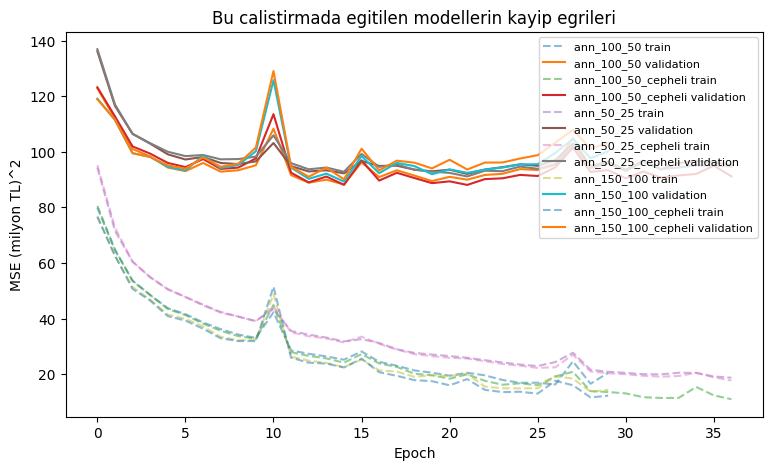

In [19]:
print(karsilastirma[["model", "cephe", "en_iyi_epoch", "val_mae_tl", "val_rmse_tl", "val_r2", "val_mape_yuzde"]].to_string(index=False))

etkiler = []
for birinci, ikinci in mimariler:
    isim = f"ann_{birinci}_{ikinci}"
    cephesiz_mae = karsilastirma.loc[karsilastirma["model"] == isim, "val_mae_tl"].iloc[0]
    cepheli_mae = karsilastirma.loc[karsilastirma["model"] == isim + "_cepheli", "val_mae_tl"].iloc[0]
    etkiler.append({
        "mimari": f"{birinci}-{ikinci}",
        "cephesiz_mae_tl": cephesiz_mae,
        "cepheli_mae_tl": cepheli_mae,
        "iyilesme_tl": cephesiz_mae - cepheli_mae,
    })

cephe_etkisi = pd.DataFrame(etkiler)
cephe_etkisi.to_csv(sonuclar_klasoru / "cephe_etkisi.csv", index=False)
print("\nCephe eklenince MAE degisimi (pozitif = iyilesme):")
print(cephe_etkisi.to_string(index=False))

plt.figure(figsize=(9, 5))
for isim, (train_gecmisi, val_gecmisi) in gecmisler.items():
    plt.plot(train_gecmisi, linestyle="--", alpha=0.5, label=isim + " train")
    plt.plot(val_gecmisi, label=isim + " validation")
plt.xlabel("Epoch")
plt.ylabel("MSE (milyon TL)^2")
plt.title("Bu calistirmada egitilen modellerin kayip egrileri")
plt.legend(fontsize=8)
plt.show()


## 8. Test (istege bagli)

En iyi model validation MAE'ye gore secilir. Eski `results/test_sonucu.csv` dosyasini korumak icin bu hucre varsayilan olarak test yapmaz. Test zaten onceki deneyde goruldugu icin bunu yeni bir bagimsiz/korkusuz test saymiyoruz. Sadece gerekirse `testi_calistir = True` yap. Sonuc ayri `test_sonucu_cephe.csv` dosyasina kaydedilir.

In [20]:
testi_calistir = False

if testi_calistir:
    en_iyi = karsilastirma.iloc[0]
    en_iyi_isim = en_iyi["model"]
    cepheli = en_iyi["cephe"] == "var"
    X_test_secili = X_test_tf_cepheli if cepheli else X_test_tf

    parametreler = model_olustur(
        int(en_iyi["katman_1"]), int(en_iyi["katman_2"]), int(X_test_secili.shape[1])
    )
    checkpoint = tf.train.Checkpoint(w1=parametreler[0], b1=parametreler[1],
                                     w2=parametreler[2], b2=parametreler[3],
                                     w3=parametreler[4], b3=parametreler[5])
    checkpoint.restore(tf.train.latest_checkpoint(str(modeller_klasoru / en_iyi_isim))).assert_existing_objects_matched()

    gercek = y_test.to_numpy(dtype=np.float64)
    tahmini = tahmin(X_test_secili, parametreler).numpy().reshape(-1).astype(np.float64) * 1_000_000
    fark = gercek - tahmini

    test_sonucu = pd.DataFrame([{
        "model": en_iyi_isim,
        "test_mae_tl": np.mean(np.abs(fark)),
        "test_rmse_tl": np.sqrt(np.mean(fark ** 2)),
        "test_r2": 1 - np.sum(fark ** 2) / np.sum((gercek - gercek.mean()) ** 2),
        "test_mape_yuzde": np.mean(np.abs(fark / np.maximum(np.abs(gercek), 1))) * 100,
    }])
    test_sonucu.to_csv(sonuclar_klasoru / "test_sonucu_cephe.csv", index=False)
    print(test_sonucu.to_string(index=False))
else:
    print("Test calistirilmadi. Karsilastirmayi validation sonuclariyla yap.")


Test calistirilmadi. Karsilastirmayi validation sonuclariyla yap.


In [21]:
model_adi = "ann_100_50_cepheli"

parametreler_test = model_olustur(100, 50, int(X_test_tf_cepheli.shape[1]))

checkpoint = tf.train.Checkpoint(
    w1=parametreler_test[0],
    b1=parametreler_test[1],
    w2=parametreler_test[2],
    b2=parametreler_test[3],
    w3=parametreler_test[4],
    b3=parametreler_test[5]
)

kayit_yolu = tf.train.latest_checkpoint(str(modeller_klasoru / model_adi))

if kayit_yolu is None:
    raise FileNotFoundError("Kaydedilmis model bulunamadi.")

checkpoint.restore(kayit_yolu).assert_existing_objects_matched()

print("Model yuklendi:", kayit_yolu)

Model yuklendi: ../models/ann_100_50_cepheli/ann-1


In [22]:
tahminler = tahmin(X_test_tf_cepheli, parametreler_test)

tahminler = tahminler.numpy().reshape(-1) * 1_000_000

gercek_fiyatlar = y_test.to_numpy()

print("Gercek fiyat:", gercek_fiyatlar[0])
print("Tahmin edilen fiyat:", tahminler[0])

Gercek fiyat: 12100000
Tahmin edilen fiyat: 12184555.0


In [23]:
mae = np.mean(np.abs(gercek_fiyatlar - tahminler))

rmse = np.sqrt(np.mean((gercek_fiyatlar - tahminler) ** 2))

r2 = 1 - np.sum((gercek_fiyatlar - tahminler) ** 2) / np.sum((gercek_fiyatlar - np.mean(gercek_fiyatlar)) ** 2)

mape = np.mean(np.abs((gercek_fiyatlar - tahminler) / gercek_fiyatlar)) * 100

print(f"MAE: {mae:,.2f} TL")
print(f"RMSE: {rmse:,.2f} TL")
print(f"R2: {r2:.4f}")
print(f"MAPE: %{mape:.2f}")

MAE: 2,545,736.09 TL
RMSE: 7,773,292.86 TL
R2: 0.7597
MAPE: %26.45


In [24]:
sonuc = pd.DataFrame({
    "model": ["ann_100_50_cepheli"],
    "MAE": [mae],
    "RMSE": [rmse],
    "R2": [r2],
    "MAPE": [mape]
})

sonuc.to_csv("../results/test_sonucu_100_50_cepheli.csv", index=False)

print("Test sonuclari kaydedildi.")

Test sonuclari kaydedildi.
